# Notebook 3 · Optimización multiobjetivo con OMOPSO

**Curso:** Optimización metaheurística orientada a modelación hidrogeológica
**UNAM · Instituto de Geología · Educación Continua y a Distancia · 17 de noviembre de 2026**
Dr. Abelardo Rodríguez Pretelín · Laboratorio HIDRA

En este notebook se muestra el uso de la herramienta **OMOPSO** como optimizador para problemas de optimización multiobjetivo: primero en un problema de
prueba con solución conocida, para aprender a usarla, y después en el acuífero de Fritz, con dos y con tres objetivos.

**Literatura:**

1. Sierra, M. R., & Coello Coello, C. A. (2005). Improving PSO-based multi-objective optimization using crowding, mutation and ε-dominance. En *International
   Conference on Evolutionary Multi-Criterion Optimization* (pp. 505–519). Springer.
2. Coello, C. C., & Lechuga, M. S. (2002). MOPSO: A proposal for multiple objective particle swarm optimization. En *Proceedings of the 2002 Congress on
   Evolutionary Computation, CEC'02* (Vol. 2, pp. 1051–1056). IEEE.

---

### Cómo usar este cuaderno

- Ejecuta las celdas **en orden** con `Shift + Enter`. Algunas celdas tardan cerca de un minuto (lo dicen arriba): déjalas correr.
- Las celdas ✏️ **Inténtalo** son para cambiar un número y volver a ejecutar.

| Sección | Programa | Qué se hace |
|---|---|---|
| 1 | 3.3 y 3.4 · implementación y problema introductorio | OMOPSO con DTLZ3: cómo se usa, paso a paso, y siete ejemplos de uso |
| 2 | 3.1 y 3.5 · conceptos y problema hidrogeológico | el problema del original con **dos** objetivos en el acuífero de Fritz: el frente es una curva |
| 3 | 3.5 · problema hidrogeológico | el problema del original con sus **tres** objetivos: el frente es una cinta curva |
| 4 | puente | la matriz, su campo y la geología |

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 0 · PREPARACIÓN</p>

## 0 · Preparación (2 min)

`pyOMOPSO` es la implementación del laboratorio del optimizador de Sierra y Coello (2005); vive en `Información/codigo/pyOMOPSO` de esta sesión.
En la versión original se instalaba `ray` para correr en paralelo; aquí usamos `parOMOPSO_det`, la misma función sin `ray`, que da los mismos resultados con la misma semilla.

Importar dependencias:

In [1]:
import sys; sys.path.append('..'); sys.path.append('Información/codigo/pyOMOPSO')
import time
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d

import hidra
from Test_Functions import *                                   # las funciones de prueba (DTLZ3)
from ParOMOPSO_det import parOMOPSO_det as parOMOPSO           # el optimizador (en el original: from ParOMOPSO import parOMOPSO)
from Mat_cost import *                                         # mat_cost: los costos del archivo como arreglo

def frente(e_file):
    # El archivo de OMOPSO es una lista de partículas. Esta función saca dos tablas:
    # F (una fila por solución, una columna por objetivo) y X (una fila por solución, una columna por variable).
    F = np.array([np.ravel(s['cost']) for s in e_file])
    X = np.array([np.ravel(s['position']) for s in e_file])
    return F, X

hidra.verificar_entorno()

Python 3.11.14 | numpy 2.4.6 | scipy 1.17.1 | matplotlib 3.11.2 | plotly 7.1.0 | otter 7.0.0


Simulador listo: una corrida tarda 0.26 s. Resultado(bombeos=[100.0, 100.0, 100.0] m³/d → abatimientos en pozos=[0.90, 0.92, 0.92] m, humedal=0.48 m)
ENTORNO LISTO


<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 1 · OMOPSO CON UN PROBLEMA DE PRUEBA · PROGRAMA 3.3 Y 3.4</p>

## 1 · OMOPSO con un problema de prueba: DTLZ3 (20 min)

Antes de usar un optimizador en un acuífero conviene usarlo donde **conocemos la respuesta**. DTLZ3 (Deb y otros, 2005) es un problema de prueba con
tres objetivos cuyo frente de Pareto se conoce de antemano.

### Función de prueba (DTLZ3) para M = 3

$$
\begin{aligned}
f_1(\mathbf{x}) &= \bigl(1 + g(\mathbf{x})\bigr)\,\cos\!\bigl(x_1\tfrac{\pi}{2}\bigr)\,\cos\!\bigl(x_2\tfrac{\pi}{2}\bigr),\\
f_2(\mathbf{x}) &= \bigl(1 + g(\mathbf{x})\bigr)\,\cos\!\bigl(x_1\tfrac{\pi}{2}\bigr)\,\sin\!\bigl(x_2\tfrac{\pi}{2}\bigr),\\
f_3(\mathbf{x}) &= \bigl(1 + g(\mathbf{x})\bigr)\,\sin\!\bigl(x_1\tfrac{\pi}{2}\bigr),
\end{aligned}
\qquad 0 \le x_i \le 1
$$

**donde** $g(\mathbf{x}) \ge 0$ mide qué tan lejos está una decisión del frente. En `pyOMOPSO` es $g(\mathbf{x}) = (x_3 - 0.5)^2$: con $x_3 = 0.5$ vale cero y entonces

$$
f_1^2 + f_2^2 + f_3^2 = (1 + g)^2 = 1 ,
$$

el **octante de una esfera de radio 1**. $x_1$ y $x_2$ dicen **dónde** sobre la esfera; $x_3$, **qué tan lejos** de ella. (La DTLZ3 de Deb usa una $g$ con cosenos
que llena el espacio de frentes locales; la de `pyOMOPSO` es más sencilla, con un solo frente: sirve para aprender y para validar.)

### 1.1 Definición de la función objetivo

In [2]:
# Define Optimization Problem
Prueba = dtlz3()
Test_function = Prueba.Test_function

f = Test_function([0.3, 0.6, 0.5])          # una decisión: devuelve una COLUMNA con los tres objetivos
print(f)
print("radio de esta decisión:", round(float(np.linalg.norm(f)), 4), "-> con x3 = 0.5 está sobre la esfera")

[[0.5237]
 [0.7208]
 [0.454 ]]
radio de esta decisión: 1.0 -> con x3 = 0.5 está sobre la esfera


Fíjate en la forma de la salida: OMOPSO espera que la función objetivo reciba un vector de decisión y devuelva **una columna** (un objetivo por renglón).
Con $x_3 = 0.5$ la decisión está sobre la esfera: la suma de los cuadrados de sus tres objetivos es 1.

### 1.2 Definir las condiciones del problema

In [3]:
problem = {
        'CostFunction': Test_function,
        'nVar': 3,
        'VarMin': 0,   # Alternatively you can use a "numpy array" with nVar elements, instead of scalar
        'VarMax': 1,    # Alternatively you can use a "numpy array" with nVar elements, instead of scalar
    }

# Define algorithm variables
OMOPSO = {
        'MaxIter': 75,
        'nPop': 40,
        'w1': 0.1,
        'w2': 0.5,
        'e': 0.001,
        'c1': 1.5,
        'c2': 2,
        'nGrid': 7,
        'alpha': 0.1,
        'wdamp': 0.99,
        'r1': 0,
        'r2': 1,
        'verbose': 0,
    }

**Qué es cada parámetro.** OMOPSO es el enjambre de la sesión 2 con cuatro piezas nuevas:

| Parámetro | Qué es | Aquí |
|---|---|---|
| `nPop`, `MaxIter` | partículas e iteraciones, como en PSO | 40 y 75 (el original usa 150; con DTLZ3 el archivo crece mucho y 75 bastan) |
| `w1`, `w2` | la inercia se sortea entre estos dos valores en cada paso | 0.1 y 0.5 |
| `c1`, `c2` | los coeficientes cognitivo y social se sortean entre estos dos valores | 1.5 y 2 |
| `r1`, `r2` | rango de los números al azar | 0 y 1 |
| `e` | el ε del **archivo ε-dominante** | 0.001 |
| `nGrid`, `alpha` | la rejilla que mide el **hacinamiento** para elegir líderes en zonas poco pobladas | 7 y 0.1 |
| `wdamp` | amortiguamiento de la inercia | 0.99 |
| `verbose` | 1 imprime el avance; 0 trabaja en silencio | 0 |

**Las ecuaciones.** La partícula $i$ se mueve como en PSO, con los coeficientes **sorteados** en cada paso y un **líder** tomado del repositorio de no dominadas:

$$
\mathbf{v}_i^{t+1} = W\,\mathbf{v}_i^{t} + R_1 C_1\,\big(\mathbf{p}_i - \mathbf{x}_i^{t}\big) + R_2 C_2\,\big(\mathbf{l}_i - \mathbf{x}_i^{t}\big), \qquad
\mathbf{x}_i^{t+1} = \mathbf{x}_i^{t} + \mathbf{v}_i^{t+1}
$$

**donde** $W \sim U(w_1, w_2)$, $C_1, C_2 \sim U(c_1, c_2)$ y $R_1, R_2 \sim U(r_1, r_2)$; $\mathbf{p}_i$ es la mejor posición de la partícula y $\mathbf{l}_i$ su líder.

- **Hacinamiento (crowding).** No hay un «mejor del enjambre»: hay un frente. El líder se elige del repositorio prefiriendo las soluciones con más espacio alrededor:
  $CD_k = \sum_{m} \big|f_m^{(k+1)} - f_m^{(k-1)}\big| \,/\, \big|f_m^{\max} - f_m^{\min}\big|$, con las vecinas de $k$ en el orden de cada objetivo (las de los extremos valen $\infty$).
- **ε-dominancia.** El archivo final divide el espacio de objetivos en cajas logarítmicas $B_m = \lfloor \ln f_m / \ln(1 + \varepsilon) \rfloor$ y guarda a lo más una
  solución por caja. Por eso **los objetivos deben ser positivos**, y por eso $\varepsilon$ decide qué tan fino es el menú.
- **Mutación.** Un tercio del enjambre muta en todo el rango, otro con un radio $p_m = (1 - t/(T-1))^{n}$ que se apaga con las iteraciones ($n$ = número de
  variables) y otro no muta. Sacudir al principio evita que todo el enjambre caiga en una sola zona.

#### El algoritmo por dentro: cada paso del pseudocódigo y su archivo

`parOMOPSO` es una caja que se puede abrir: cada paso del pseudocódigo de la lámina vive en un archivo de `Información/codigo/pyOMOPSO`.

| Paso del pseudocódigo | Archivo | Función |
|---|---|---|
| 1 · crear el enjambre al azar y evaluarlo | `Particle_creation_det.py` | `particle_creation` |
| 2 · marcar las no dominadas: el repositorio de líderes | `Domination.py` | `determine_domination` |
| 3 · elegir a cada partícula un líder, prefiriendo las zonas poco pobladas | `Sel_Leader.py` | `SelectLeader` |
| 4 · mover cada partícula: velocidad y posición (las ecuaciones de PSO) | `Particle_loop_det.py` | `particle_loop` |
| 5 · mutar, con probabilidad que baja con las iteraciones | `mutate.py` | `mutate` |
| 6 · actualizar el repositorio y recortarlo por hacinamiento | `Domination.py`, `Crow_leaders.py` | `determine_domination`, `crowding_leaders` |
| 7 · actualizar el archivo externo con ε-dominancia (la respuesta, `e_file`) | `Rep_dominance.py` | `Repository_dominance` |

El bucle que los une, iteración por iteración, es `parOMOPSO_det` en `ParOMOPSO_det.py`. ✏️ **Inténtalo:** ábrelo y encuentra la línea de la
probabilidad de mutación `pm`.

### 1.3 Correr OMOPSO

In [4]:
# Running par_OMOPSO (esta celda tarda alrededor de un minuto)
print('Running parOMOPSO ...')
np.random.seed(42); t0 = time.time()
e_file, rep, rep_time = parOMOPSO(problem, OMOPSO)
print(f'listo: {len(e_file)} soluciones en el archivo, en {time.time() - t0:.0f} s')

Running parOMOPSO ...


listo: 442 soluciones en el archivo, en 49 s


### 1.4 Visualizar resultados

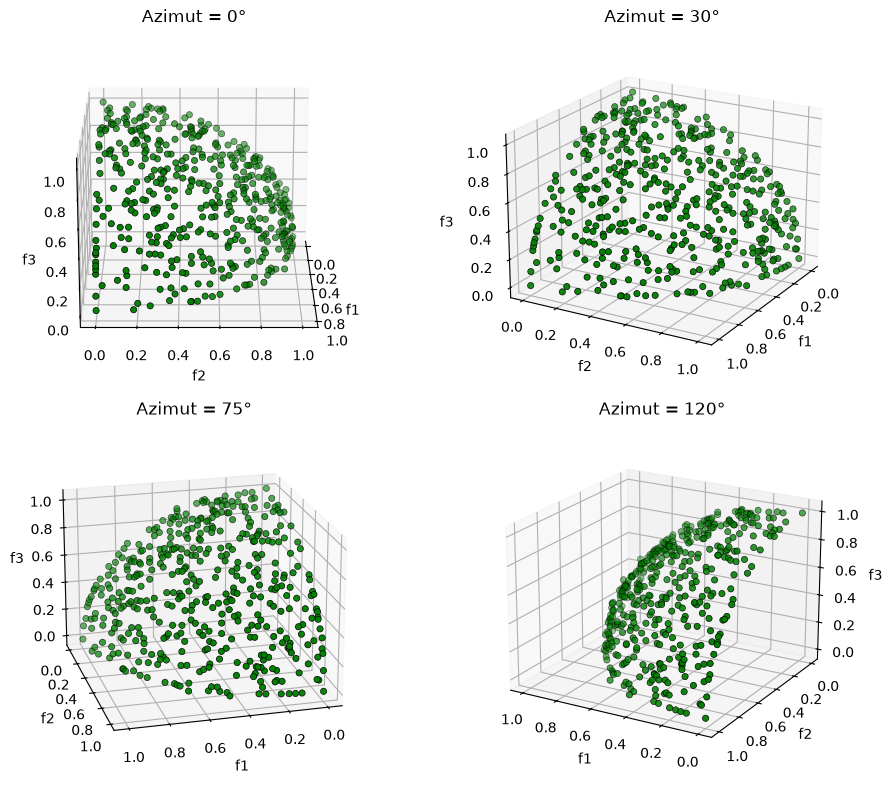

In [5]:
x = []
y = []
z = []

costos = mat_cost(e_file)

for i in range(0, len(e_file)):

    mat_vector = costos[:, 0]
    cost_vector = mat_vector[i]
    x.append(cost_vector[0])
    y.append(cost_vector[1])
    z.append(cost_vector[2])

# Distintos ángulos de azimut que queremos usar
azimuts = [0, 30, 75, 120]
elevacion = 20
fig = plt.figure(figsize=(10, 8))
for i, azim in enumerate(azimuts):
    ax = fig.add_subplot(2, 2, i + 1, projection='3d')
    ax.scatter3D(x, y, z, color="green", edgecolors="black", linewidths=.5, label="Frente de Pareto")
    ax.set_xlabel("f1"); ax.set_ylabel("f2"); ax.set_zlabel("f3"); ax.set_title(f"Azimut = {azim}°")
    ax.view_init(elev=elevacion, azim=azim)
plt.tight_layout(); plt.show()

# El mismo frente, interactivo: arrastra para girar, rueda para acercar, doble clic para volver a la vista inicial.
# (hidra.frente_3d usa plotly; cada fila de F es una solución y cada columna un objetivo)
F = np.column_stack([x, y, z])
fig = hidra.frente_3d((F, "Frente de Pareto"), ejes=("f1", "f2", "f3"), titulo="DTLZ3: el octante de la esfera que encontró OMOPSO")
fig.show()

### 1.5 ¿Qué tan cerca del frente verdadero?

Como el frente verdadero es la esfera, el radio de cada solución debería ser 1. Es la prueba de que el algoritmo está funcionando.

radio medio = 1.0058  (verdadero: 1)   mínimo 1.0000   máximo 1.0456
desviación media al frente verdadero: 0.58 %


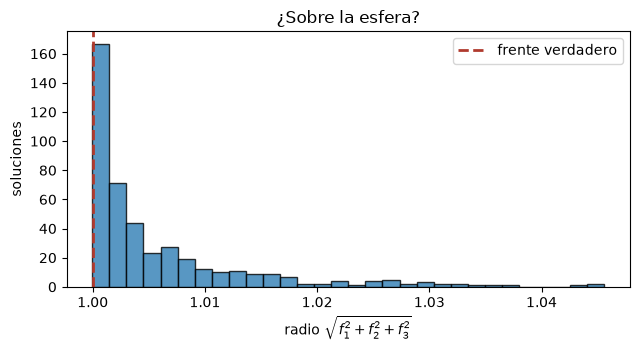

In [6]:
F_dtlz3, X_dtlz3 = frente(e_file)
radios = np.linalg.norm(F_dtlz3, axis=1)
print(f"radio medio = {radios.mean():.4f}  (verdadero: 1)   mínimo {radios.min():.4f}   máximo {radios.max():.4f}")
print(f"desviación media al frente verdadero: {abs(radios - 1).mean() * 100:.2f} %")
plt.figure(figsize=(6.5, 3.6))
plt.hist(radios, bins=30, color='#2E7DB5', edgecolor='k', alpha=0.8); plt.axvline(1, color='#B03A2E', ls='--', lw=2, label='frente verdadero')
plt.xlabel('radio $\\sqrt{f_1^2+f_2^2+f_3^2}$'); plt.ylabel('soluciones'); plt.legend(); plt.title('¿Sobre la esfera?'); plt.tight_layout(); plt.show()

### 1.6 Ejemplos de uso del algoritmo

Ya corrió una vez. Ahora, siete ejemplos cortos para aprender a **usar** OMOPSO: qué devuelve, qué mover y qué esperar. Todos con DTLZ3, donde
sabemos la respuesta, y con menos iteraciones para que sean rápidos.

#### Ejemplo 1 · ¿Qué devuelve OMOPSO?

`parOMOPSO` devuelve tres cosas: el **archivo ε** (`e_file`, el frente final, una solución por caja), el **repositorio** (`rep`, las no dominadas de la
última iteración, de donde salen los líderes) y los tiempos. Cada solución es un diccionario con su posición (las variables) y su costo (los objetivos).

In [7]:
print("soluciones en el archivo ε:", len(e_file), " | en el repositorio:", len(rep))
s = e_file[0]
print("una solución tiene las llaves:", list(s.keys()))
print("  position (las variables x1, x2, x3):", np.round(np.ravel(s['position']), 4))
print("  cost     (los objetivos f1, f2, f3): ", np.round(np.ravel(s['cost']), 4))
print("la función frente() las pasa a tablas:", F_dtlz3.shape, "(soluciones x objetivos) y", X_dtlz3.shape, "(soluciones x variables)")
print("x3 de todas las soluciones: media", round(X_dtlz3[:, 2].mean(), 3), "-> el optimizador descubrió que x3 = 0.5 pone a la solución sobre la esfera")

soluciones en el archivo ε: 442  | en el repositorio: 40
una solución tiene las llaves: ['position', 'velocity', 'cost', 'best_position', 'best_cost', 'is_dominated', 'grid_index', 'grid_subindex', 'crowding_distance', 'New_pos', 'New_cost', 'Mutation']
  position (las variables x1, x2, x3): [0.0581 0.8662 0.6011]
  cost     (los objetivos f1, f2, f3):  [0.2099 0.9839 0.092 ]
la función frente() las pasa a tablas: (442, 3) (soluciones x objetivos) y (442, 3) (soluciones x variables)
x3 de todas las soluciones: media 0.508 -> el optimizador descubrió que x3 = 0.5 pone a la solución sobre la esfera


#### Ejemplo 2 · ¿Cuántas iteraciones hacen falta?

Con pocas iteraciones el enjambre todavía está lejos del frente y lo cubre mal. Corremos con 5 y 20 iteraciones y comparamos con las 75 de arriba.

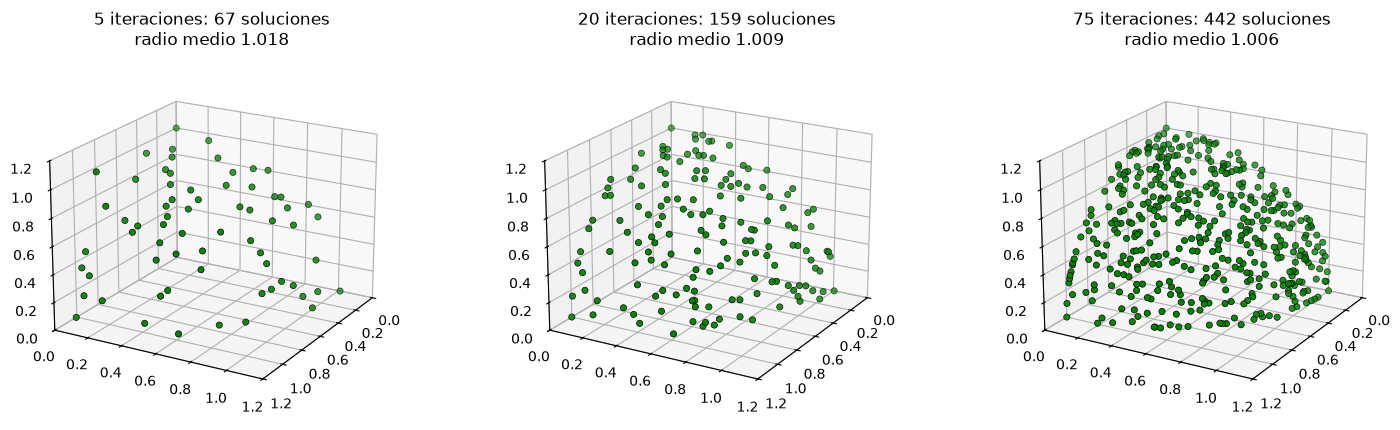

In [8]:
fig = plt.figure(figsize=(15, 4.4))
frentes_it, color_it = [], ["#c9a227", "#5a8f5a", "#2e9b4f"]
for n, it in enumerate([5, 20, 75]):
    if it == 75:
        F_it = F_dtlz3
    else:
        np.random.seed(42)
        ef_it, _, _ = parOMOPSO(problem, dict(OMOPSO, MaxIter=it))
        F_it, _ = frente(ef_it)
    r_it = np.linalg.norm(F_it, axis=1)
    ax = fig.add_subplot(1, 3, n + 1, projection='3d')
    ax.scatter3D(F_it[:, 0], F_it[:, 1], F_it[:, 2], color="green", edgecolors="black", linewidths=.5)
    ax.set_xlim(0, 1.2); ax.set_ylim(0, 1.2); ax.set_zlim(0, 1.2); ax.view_init(elev=20, azim=30)
    ax.set_title(f"{it} iteraciones: {len(F_it)} soluciones\nradio medio {r_it.mean():.3f}")
    frentes_it.append((F_it, f"{it} iteraciones", color_it[n], 3 if it < 75 else 4))
plt.tight_layout(); plt.show()

# Las tres nubes juntas, para girarlas con el mouse y ver cómo se acercan a la esfera
hidra.frente_3d(*frentes_it, ejes=("f1", "f2", "f3"), titulo="5, 20 y 75 iteraciones (gira para compararlas)", alto=520).show()

Dos cosas mejoran con las iteraciones: la **convergencia** (el radio medio se acerca a 1) y la **cobertura** (más soluciones repartidas por todo el octante).
En un problema real no conocemos el radio: se corre hasta que el frente deja de cambiar.

#### Ejemplo 3 · El ε del archivo: ¿qué tan fino quieres el menú?

El ε fija el tamaño de las cajas del archivo. Un ε grande guarda pocas soluciones bien repartidas; uno pequeño guarda muchas.

In [9]:
for eps in [0.05, 0.01, 0.001]:
    np.random.seed(42); t0 = time.time()
    ef_e, _, _ = parOMOPSO(problem, dict(OMOPSO, MaxIter=40, e=eps))
    F_e, _ = frente(ef_e)
    print(f"ε = {eps:<6} -> {len(F_e):4d} soluciones en el archivo, radio medio {np.linalg.norm(F_e, axis=1).mean():.4f}  ({time.time() - t0:.0f} s)")

ε = 0.05   ->   33 soluciones en el archivo, radio medio 1.0054  (1 s)


ε = 0.01   ->  201 soluciones en el archivo, radio medio 1.0058  (8 s)


ε = 0.001  ->  272 soluciones en el archivo, radio medio 1.0069  (11 s)


El ε no cambia **dónde** está el frente, cambia **cuántas** soluciones te entrega. Para una presentación a la autoridad quizá bastan 20 opciones bien
distintas; para analizar el frente conviene un ε pequeño.

#### Ejemplo 4 · La semilla: cada corrida es distinta

OMOPSO es estocástico, como el enjambre de la sesión 2. Dos semillas dan dos archivos distintos; lo que debe repetirse es la **calidad**.

In [10]:
for semilla in [1, 2]:
    np.random.seed(semilla)
    ef_s, _, _ = parOMOPSO(problem, dict(OMOPSO, MaxIter=40))
    F_s, _ = frente(ef_s)
    print(f"semilla {semilla}: {len(F_s)} soluciones, radio medio {np.linalg.norm(F_s, axis=1).mean():.4f}")

semilla 1: 229 soluciones, radio medio 1.0080


semilla 2: 277 soluciones, radio medio 1.0059


✏️ **Inténtalo:** cambia las semillas. ¿Cuánto varía el número de soluciones? ¿Y el radio medio? Reportar una sola corrida es como reportar una sola
semilla en la sesión 2.

#### Ejemplo 5 · Tu propia función objetivo

Para resolver **tu** problema basta escribir una función que reciba el vector de decisión y devuelva **una columna** con los objetivos, todos para
minimizar y **positivos** (el archivo ε usa logaritmos). Lo probamos con otro problema de frente conocido, ZDT1 (Zitzler, Deb y Thiele, 2000), de dos objetivos:

$$
f_1 = x_1, \qquad g = 1 + \frac{9}{n-1}\sum_{i=2}^{n} x_i, \qquad f_2 = g\left(1 - \sqrt{f_1 / g}\right), \qquad 0 \le x_i \le 1
$$

Su frente verdadero es $f_2 = 1 - \sqrt{f_1}$ (con $g = 1$, es decir, $x_2 = \dots = x_n = 0$). Sumamos 0.01 a los dos objetivos para que nunca valgan cero.

122 soluciones en 7 s; desviación media a la curva verdadera: 0.0024


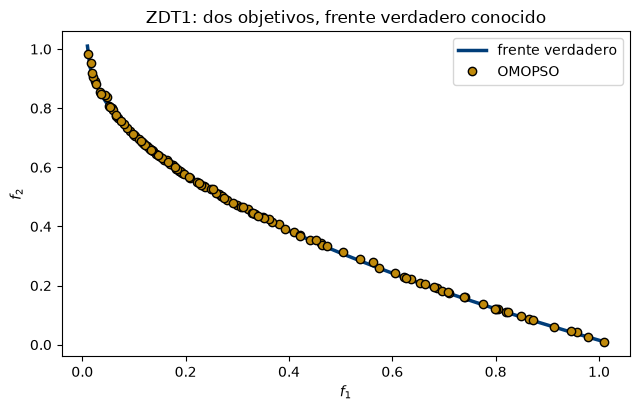

In [11]:
def zdt1(x):
    x = np.asarray(x, dtype=float)
    f1 = x[0]
    g = 1 + 9 * np.sum(x[1:]) / (len(x) - 1)
    f2 = g * (1 - np.sqrt(f1 / g))
    return np.array([[f1 + 0.01, f2 + 0.01]]).T          # una columna, objetivos positivos

problema_zdt1 = {'CostFunction': zdt1, 'nVar': 5, 'VarMin': 0, 'VarMax': 1}
np.random.seed(42); t0 = time.time()
ef_z, _, _ = parOMOPSO(problema_zdt1, dict(OMOPSO, MaxIter=100))
F_z, X_z = frente(ef_z)
f1v = np.linspace(0, 1, 200)
print(f"{len(F_z)} soluciones en {time.time() - t0:.0f} s; desviación media a la curva verdadera: "
      f"{np.mean(np.abs((F_z[:, 1] - 0.01) - (1 - np.sqrt(F_z[:, 0] - 0.01)))):.4f}")
plt.figure(figsize=(6.5, 4.2))
plt.plot(f1v + 0.01, 1 - np.sqrt(f1v) + 0.01, '-', color='#003D79', lw=2.5, label='frente verdadero')
plt.plot(F_z[:, 0], F_z[:, 1], 'o', mfc='#C08A0B', mec='k', ms=6, label='OMOPSO')
plt.xlabel('$f_1$'); plt.ylabel('$f_2$'); plt.legend(); plt.title('ZDT1: dos objetivos, frente verdadero conocido'); plt.tight_layout(); plt.show()

La receta es siempre la misma: **(1)** una función que devuelve una columna de objetivos positivos, **(2)** el diccionario `problem` con el número de
variables y sus límites, **(3)** el diccionario de parámetros, **(4)** `parOMOPSO`. Con dos objetivos el frente es una **curva**; con tres, una **superficie**.

#### Ejemplo 6 · Elegir una solución del frente

Un frente no es una decisión: es un menú. La regla del cuaderno original: normalizar cada objetivo de 0 (lo mejor) a 1 (lo peor) y elegir la solución
**más cercana al origen**, el punto ideal donde todos los objetivos son perfectos a la vez:

$$
\tilde{f}_m = \frac{f_m - f_m^{\min}}{f_m^{\max} - f_m^{\min}}, \qquad
k^{c} = \arg\min_{k} \big\| \tilde{\mathbf{F}}_k \big\|_2 = \arg\min_k \sqrt{\textstyle\sum_m \tilde{f}_{m,k}^2}
$$

solución de compromiso de ZDT1: f1 = 0.393, f2 = 0.391 (variables [0.383 0.    0.    0.    0.   ])


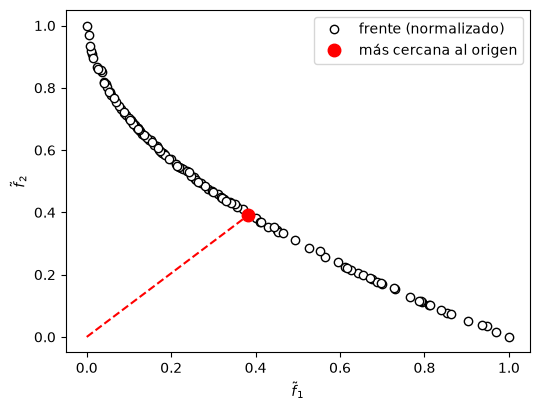

In [12]:
Fn_z = (F_z - F_z.min(0)) / (F_z.max(0) - F_z.min(0))
k_z = int(np.argmin(np.linalg.norm(Fn_z, axis=1)))
print(f"solución de compromiso de ZDT1: f1 = {F_z[k_z, 0]:.3f}, f2 = {F_z[k_z, 1]:.3f} (variables {np.round(X_z[k_z], 3)})")
plt.figure(figsize=(5.5, 4.2))
plt.plot(Fn_z[:, 0], Fn_z[:, 1], 'o', mfc='white', mec='k', ms=6, label='frente (normalizado)')
plt.plot(*Fn_z[k_z], 'o', color='red', ms=9, label='más cercana al origen')
plt.plot([0, Fn_z[k_z, 0]], [0, Fn_z[k_z, 1]], '--', color='red')
plt.xlabel('$\\tilde f_1$'); plt.ylabel('$\\tilde f_2$'); plt.legend(); plt.tight_layout(); plt.show()

#### Ejemplo 7 · Más de tres objetivos: coordenadas paralelas

Con cuatro o más objetivos ya no hay gráfica 3-D. Cada eje vertical es un objetivo y cada línea una solución; las líneas que se **cruzan** entre dos ejes
delatan el conflicto. Lo practicamos con el frente de DTLZ3.

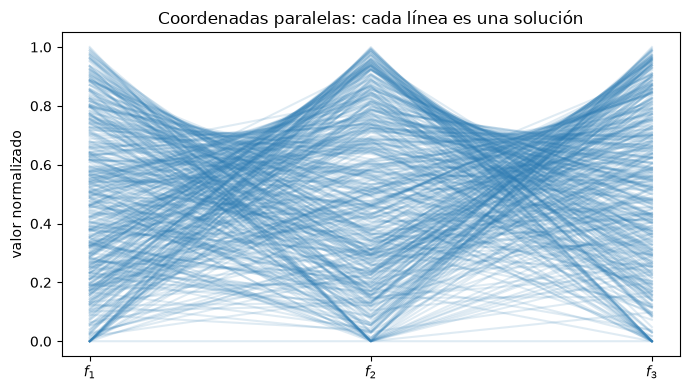

In [13]:
Fn = (F_dtlz3 - F_dtlz3.min(0)) / (F_dtlz3.max(0) - F_dtlz3.min(0))
plt.figure(figsize=(7, 4))
for fila in Fn:
    plt.plot([0, 1, 2], fila, color='#2E7DB5', alpha=0.15)
plt.xticks([0, 1, 2], ['$f_1$', '$f_2$', '$f_3$']); plt.ylabel('valor normalizado'); plt.title('Coordenadas paralelas: cada línea es una solución')
plt.tight_layout(); plt.show()

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 2 · EL PROBLEMA HIDROGEOLÓGICO CON DOS OBJETIVOS · PROGRAMA 3.1 Y 3.5</p>

## 2 · El acuífero de Fritz con dos objetivos (22 min)

Pasamos al problema hidrogeológico del cuaderno original, ahora sobre el acuífero de Fritz que simulamos con `hidra` desde la sesión 1. Primero lo
acotamos a **dos objetivos**, para poder dibujar todo y entender los conceptos; en la sección 3 lo completamos con tres.

### 2.1 Definición de las funciones objetivo

Las variables de decisión son los bombeos de los tres pozos, $\mathbf{p} = (p_1, p_2, p_3)$ en m³/d, entre 0 y 500. El abatimiento en cada pozo y en el
humedal sale de la matriz de respuesta fabricada con el simulador: $s_i(\mathbf{p}) = \sum_j \alpha_{ij}\,p_j$ y $s_h(\mathbf{p}) = \sum_j \alpha_{h,j}\,p_j$.

#### Función objetivo 1 · costo del bombeo

Representa el costo del bombeo realizado (función objetivo 2 del cuaderno original).

$$
\text{Costo} \;=\; \sum_{i=1}^{M^{p}=3} c_{i}\,\bigl[p_{i}\,\bigl(\text{H}_{i} - h_{i}\bigr)\bigr]
$$

**donde**:

- $p_i$ es la **tasa de bombeo** en el pozo $i$.
- $c_{i}$ es el **coeficiente** del costo: cuánto cuesta subir un m³/d un metro en el pozo $i$.
- $\text{H}_{i}$ es la **cota de la superficie del terreno** en el pozo $i$.
- $h_{i}$ es el **nivel del agua subterránea** en el pozo $i$. Por tanto, $\text{H}_{i} - h_{i}$ es la «altura» que hay que bombear.

Con el simulador, el nivel baja con el propio bombeo: $h_i = h_i^0 - s_i(\mathbf{p})$. La altura de bombeo crece con el abatimiento y el costo deja de ser lineal:

$$
\text{Costo}(\mathbf{p}) = \sum_{i=1}^{3} c_i\,p_i\,\big(\text{H}_i - h_i^0 + s_i(\mathbf{p})\big)
$$

con $c = (0.01,\ 0.015,\ 0.02)$, $\text{H} = (40,\ 40,\ 40)$ m y $h^0 = (34,\ 34,\ 15)$ m: los pozos 1 y 2 están junto al humedal, donde el nivel freático
está somero (6 m de profundidad); el pozo 3 está en un bloque donde el agua está a 25 m.

#### Función objetivo 2 · índice de necesidad no cubierta

Es la función objetivo 3 del cuaderno original:

$$
I(\mathbf{p}) \;=\; \sum_{i=1}^{M^{p}=3} \exp\bigl(-k \,\bigl[c_i^0 + a_i\,p_i\bigr]\bigr)
$$

**donde**:

- $c_i^0$ es el **nivel base** del pozo $i$ antes del bombeo: $c^0 = (2.0,\ 1.5,\ 0.8)$.
- $a_i$ es el **coeficiente de proporcionalidad del bombeo** en el pozo $i$: $a = (0.010,\ 0.020,\ 0.015)$ por m³/d (los del original, que usaba bombeos de 0 a 100).
- $k = 0.5$ es el **coeficiente de sensibilidad**.

En el original se presentó como un índice de sostenibilidad; pero al **minimizarlo**, lo que premia es bombear. Aquí lo leemos como lo que mide: la
**necesidad de agua que queda sin cubrir** en los sectores que abastece cada pozo. Sin bombeo es máxima; cada m³/d la reduce, pero cada vez menos
(**rendimientos decrecientes**: la exponencial). Es positivo, como lo pide el archivo ε.

#### Restricciones

$$
s_i(\mathbf{p}) \le 3\ \text{m},\quad i = 1, 2, 3; \qquad s_h(\mathbf{p}) \le 1.25\ \text{m}; \qquad 0 \le p_i \le 500\ \text{m³/d}
$$

El humedal hace aquí el papel del **arroyo** del original ($\Delta q^f \le 1\,400$): el límite ambiental de la sesión 1.

| Cuaderno original | Aquí |
|---|---|
| matriz $\alpha$ de Peralta (tabla) | matriz $\alpha$ de Fritz, fabricada con el simulador (`hidra`) |
| restricción del arroyo $\beta \cdot p \le 1\,400$ | restricción del humedal $\alpha_h \cdot p \le 1.25$ m |
| bombeos de 0 a 100 | bombeos de 0 a 500 m³/d |
| costo e índice con $c_i$, $\text{H}_i$, $h_i^0$, $c_i^0$, $\alpha_i$, $k$ | los mismos coeficientes, con la altura que crece al abatir |

In [14]:
alpha = hidra.matriz_respuesta()          # abatimiento en los pozos por cada m³/d de cada pozo (sesión 1)
alpha_h = hidra.coeficientes_humedal()    # lo mismo, en el humedal
C_QP  = np.array([0.01, 0.015, 0.02])     # coeficiente de costo de cada pozo
GSLEV = np.array([40.0, 40.0, 40.0])      # cota del terreno en cada pozo [m]
H0    = np.array([34.0, 34.0, 15.0])      # nivel estático en cada pozo [m]
C_BASE = np.array([2.0, 1.5, 0.8])        # nivel base del índice
A_IDX  = np.array([0.10, 0.20, 0.15]) / 10   # coeficientes del original, para bombeos en m³/d de 0 a 500
K_IDX  = 0.5
S_HUM, P_MAX = 1.25, 500.0

def evaluar(p):
    # Todo lo de una decisión p = (p1, p2, p3): abatimientos y los objetivos de las secciones 2 y 3.
    p = np.asarray(p, dtype=float)
    s = alpha @ p                                            # abatimiento en los pozos
    return {'s': s, 'humedal': alpha_h @ p,
            'costo': np.sum(C_QP * p * (GSLEV - H0 + s)),
            'indice': np.sum(np.exp(-K_IDX * (C_BASE + A_IDX * p)))}

for nombre, p in {'A': (300, 100, 200), 'B': (100, 300, 200), 'C': (150, 50, 100)}.items():
    e = evaluar(p)
    print(f"decisión {nombre} = {p}: costo {e['costo']:6.1f} | índice {e['indice']:.3f} | humedal {e['humedal']:.3f} m | pozos {np.round(e['s'], 2)} m")

decisión A = (300, 100, 200): costo  143.3 | índice 0.405 | humedal 0.939 m | pozos [2.37 1.23 1.85] m
decisión B = (100, 300, 200): costo  152.5 | índice 0.396 | humedal 0.968 m | pozos [1.22 2.44 1.83] m
decisión C = (150, 50, 100): costo   67.6 | índice 0.777 | humedal 0.470 m | pozos [1.18 0.62 0.92] m


Igual que en el cuaderno original, veamos cómo se comporta el índice: un mapa de calor con el pozo 3 fijo.

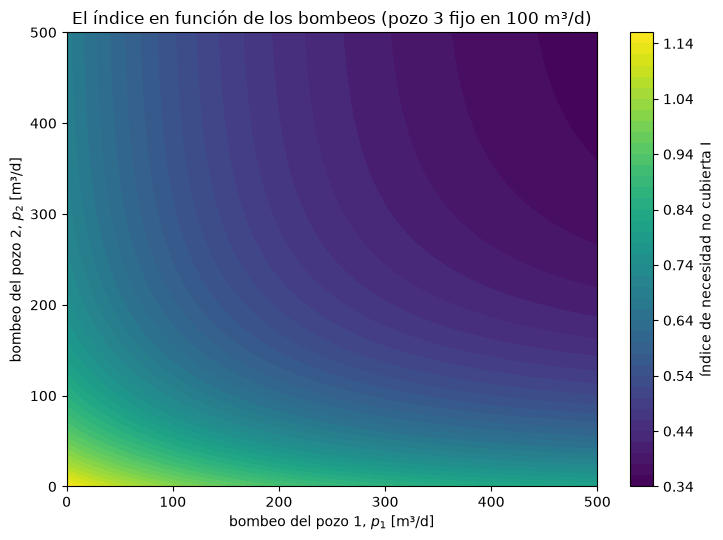

In [15]:
P1, P2 = np.meshgrid(np.linspace(0, 500, 100), np.linspace(0, 500, 100))
p3_fijo = 100
Q = np.exp(-K_IDX * (C_BASE[0] + A_IDX[0] * P1)) + np.exp(-K_IDX * (C_BASE[1] + A_IDX[1] * P2)) + np.exp(-K_IDX * (C_BASE[2] + A_IDX[2] * p3_fijo))
plt.figure(figsize=(7.5, 5.5))
contour = plt.contourf(P1, P2, Q, levels=50, cmap='viridis')
plt.colorbar(contour, label='índice de necesidad no cubierta I')
plt.xlabel('bombeo del pozo 1, $p_1$ [m³/d]'); plt.ylabel('bombeo del pozo 2, $p_2$ [m³/d]')
plt.title(f'El índice en función de los bombeos (pozo 3 fijo en {p3_fijo} m³/d)')
plt.tight_layout(); plt.show()

El índice baja al bombear, más rápido con el pozo 2 (su $a_i$ es el mayor) y cada vez más despacio: las curvas de nivel se separan. El costo, en cambio,
**sube** al bombear. Ahí está el conflicto.

### 2.2 Dominancia

Con varios objetivos, una decisión $\mathbf{a}$ **domina** a $\mathbf{b}$ ($\mathbf{a} \prec \mathbf{b}$) si no es peor en ningún objetivo y es mejor en al menos uno:

$$
\mathbf{a} \prec \mathbf{b} \iff f_m(\mathbf{a}) \le f_m(\mathbf{b}) \;\; \forall\, m \quad \text{y} \quad \exists\, m : f_m(\mathbf{a}) < f_m(\mathbf{b})
$$

Si ninguna domina a la otra, son **no dominadas** entre sí: cada una gana en algo. Ese es el conflicto, la **competitividad** entre objetivos.

In [16]:
def domina(fa, fb):
    # ¿la decisión con objetivos fa domina a la de objetivos fb? (todos se minimizan)
    return bool(np.all(fa <= fb) and np.any(fa < fb))

def objetivos2(p):
    e = evaluar(p); return np.array([e['costo'], e['indice']])

fA, fB, fC = objetivos2((300, 100, 200)), objetivos2((100, 300, 200)), objetivos2((150, 50, 100))
print("¿A domina a B?", domina(fA, fB), "| ¿B domina a A?", domina(fB, fA), " -> la misma agua, repartida distinto: B cubre más necesidad pero cuesta más")
print("¿C domina a A?", domina(fC, fA), "| ¿A domina a C?", domina(fA, fC), " -> C es más barata; A cubre más necesidad: no se dominan")

¿A domina a B? False | ¿B domina a A? False  -> la misma agua, repartida distinto: B cubre más necesidad pero cuesta más
¿C domina a A? False | ¿A domina a C? False  -> C es más barata; A cubre más necesidad: no se dominan


✏️ **Inténtalo:** busca una decisión que **domine** a A: que no cueste más y deje menos necesidad sin cubrir. Pista: mira cuál pozo baja el índice más barato.

### 2.3 Espacio de decisión, espacio de objetivos y el frente de referencia

Cada decisión vive en dos lugares: en el **espacio de decisión** (los tres bombeos) y en el **espacio de objetivos** (costo, índice). Evaluamos una malla
de decisiones cada 10 m³/d, nos quedamos con las legales y marcamos las **no dominadas**. Juntas forman el **conjunto de Pareto** y el **frente de Pareto**:

$$
\mathcal{P}^{*} = \{\, \mathbf{p} \in \Omega \;:\; \nexists\, \mathbf{q} \in \Omega,\ \mathbf{q} \prec \mathbf{p} \,\}, \qquad
\mathcal{PF}^{*} = \{\, \mathbf{F}(\mathbf{p}) \;:\; \mathbf{p} \in \mathcal{P}^{*} \,\}
$$

La malla es fina, así que su frente es una **referencia** contra la cual medir a OMOPSO, como la esfera de DTLZ3.

51941 decisiones legales de 132651; 657 no dominadas
¿relación lineal entre los objetivos sobre el frente? correlación -0.94; pendiente al inicio -0.0422 y al final -0.0002 por $ -> es una curva


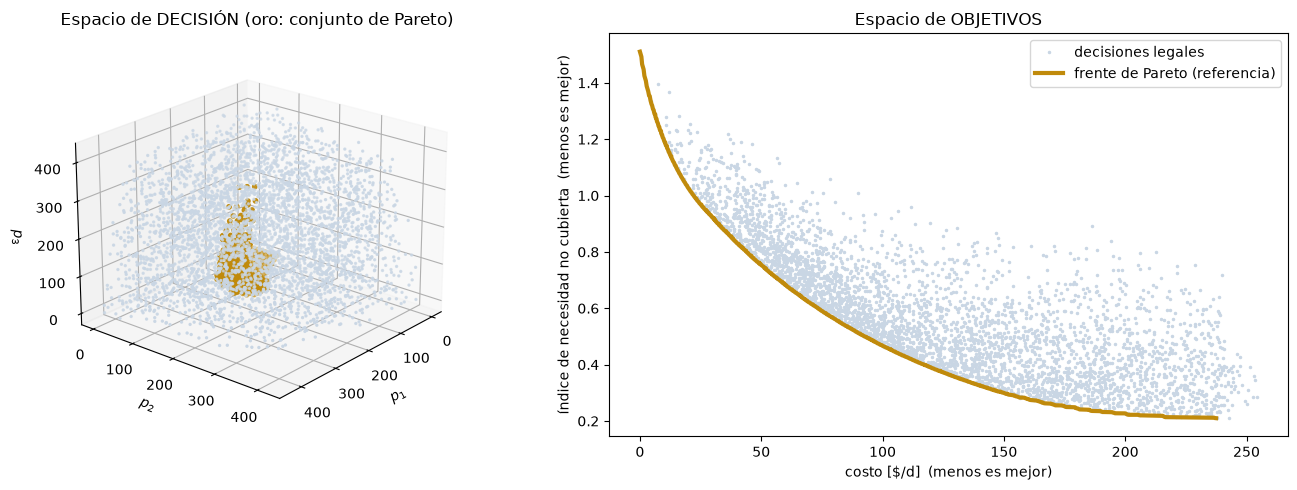

In [17]:
g = np.arange(0, 501, 10.0)
X_malla = np.array(np.meshgrid(g, g, g, indexing='ij')).reshape(3, -1).T      # 132 651 decisiones
S_malla = X_malla @ alpha.T
legal = (S_malla <= 3).all(axis=1) & (X_malla @ alpha_h <= S_HUM)
X_leg, S_leg = X_malla[legal], S_malla[legal]
F_leg = np.column_stack([(C_QP * X_leg * (GSLEV - H0 + S_leg)).sum(1), np.exp(-K_IDX * (C_BASE + A_IDX * X_leg)).sum(1)])

# no dominadas en (costo, índice): ordenando por costo, una decisión es no dominada si su índice es el menor visto hasta ahora
orden = np.lexsort((F_leg[:, 1], F_leg[:, 0]))
k_ref, mejor = [], np.inf
for i in orden:
    if F_leg[i, 1] < mejor:
        k_ref.append(i); mejor = F_leg[i, 1]
F_ref2, X_ref2 = F_leg[k_ref], X_leg[k_ref]
print(f"{len(X_leg)} decisiones legales de {len(X_malla)}; {len(F_ref2)} no dominadas")
print(f"¿relación lineal entre los objetivos sobre el frente? correlación {np.corrcoef(F_ref2.T)[0, 1]:.2f}; "
      f"pendiente al inicio {(F_ref2[5, 1] - F_ref2[0, 1]) / (F_ref2[5, 0] - F_ref2[0, 0]):.4f} y al final "
      f"{(F_ref2[-1, 1] - F_ref2[-6, 1]) / (F_ref2[-1, 0] - F_ref2[-6, 0]):.4f} por $ -> es una curva")

fig = plt.figure(figsize=(14, 5))
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
muestra = np.random.default_rng(0).choice(len(X_leg), 4000, replace=False)
ax1.scatter(X_leg[muestra, 0], X_leg[muestra, 1], X_leg[muestra, 2], s=2, c='#c9d6e4')
ax1.scatter(X_ref2[:, 0], X_ref2[:, 1], X_ref2[:, 2], s=10, c='#C08A0B')
ax1.set_xlabel('$p_1$'); ax1.set_ylabel('$p_2$'); ax1.set_zlabel('$p_3$'); ax1.set_title('Espacio de DECISIÓN (oro: conjunto de Pareto)'); ax1.view_init(22, 40)
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(F_leg[muestra, 0], F_leg[muestra, 1], '.', color='#c9d6e4', ms=3, label='decisiones legales')
ax2.plot(F_ref2[:, 0], F_ref2[:, 1], '-', color='#C08A0B', lw=3, label='frente de Pareto (referencia)')
ax2.set_xlabel('costo [$/d]  (menos es mejor)'); ax2.set_ylabel('índice de necesidad no cubierta  (menos es mejor)')
ax2.set_title('Espacio de OBJETIVOS'); ax2.legend()
plt.tight_layout(); plt.show()

Lectura: el frente es una **curva convexa**, no una recta. Al principio, cada peso invertido reduce mucho la necesidad no cubierta; al final, casi nada
(rendimientos decrecientes del índice contra un costo que crece más que proporcional por el abatimiento). La pendiente de la curva es el **precio** de
cubrir un poco más de necesidad. Todo lo que queda arriba a la derecha está dominado.

### 2.4 Las restricciones dentro de OMOPSO

OMOPSO no conoce restricciones: solo minimiza lo que la función le devuelve. Hay dos maneras de castigar una decisión ilegal:

- **Castigo de muerte:** devolver objetivos enormes (por ejemplo 10⁶) y punto.
- **Castigo graduado:** sumar a cada objetivo una penalización **proporcional a cuánto se viola** la regla: $f_m + M\,v(\mathbf{p})$, con
  $v = \sum_i \max(0, s_i - 3) + \max(0, s_h - 1.25)$.

Probamos cuatro maneras, con los mismos parámetros y la misma semilla:

In [18]:
def fritz_2obj_muerte(x):
    e = evaluar(x)
    if (e['s'] > 3).any() or e['humedal'] > S_HUM:
        return np.array([[1e6, 1e6]]).T
    return np.array([[e['costo'], e['indice']]]).T

def fritz_2obj(x, M=10.0):
    e = evaluar(x)
    v = np.maximum(e['s'] - 3, 0).sum() + max(e['humedal'] - S_HUM, 0)      # cuánto se violan las reglas [m]
    return np.array([[e['costo'] + M * v, e['indice'] + M * v]]).T

parametros = dict(OMOPSO, MaxIter=150)
casos = [('castigo de muerte, bombeos de 0 a 1000', fritz_2obj_muerte, 1000),
         ('castigo graduado con M = 1000, de 0 a 1000', lambda x: fritz_2obj(x, M=1000.0), 1000),
         ('castigo graduado con M = 10, de 0 a 1000', fritz_2obj, 1000),
         ('castigo graduado con M = 10, de 0 a 500', fritz_2obj, 500)]
for nombre, funcion, vmax in casos:
    np.random.seed(42)
    ef, _, _ = parOMOPSO({'CostFunction': funcion, 'nVar': 3, 'VarMin': 0, 'VarMax': vmax}, parametros)
    print(f"{nombre:44s} -> {len(ef)} soluciones en el archivo")

/home/abelardo/UNAM/Curso Corto de optimización/Curso_V3/Session_3/Información/codigo/pyOMOPSO/Sel_Leader.py:34: RuntimeWarning: invalid value encountered in scalar divide
  d[so[i],j] = abs(cj[i+1]-cj[i-1])/abs(cj[0]-cj[-1])
/home/abelardo/UNAM/Curso Corto de optimización/Curso_V3/Session_3/Información/codigo/pyOMOPSO/Crow_leaders.py:33: RuntimeWarning: invalid value encountered in scalar divide
  d[so[i],j] = abs(cj[i+1]-cj[i-1])/abs(cj[0]-cj[-1])


castigo de muerte, bombeos de 0 a 1000       -> 1 soluciones en el archivo


castigo graduado con M = 1000, de 0 a 1000   -> 1 soluciones en el archivo


castigo graduado con M = 10, de 0 a 1000     -> 68 soluciones en el archivo


castigo graduado con M = 10, de 0 a 500      -> 128 soluciones en el archivo


Tres lecciones:

1. Con el **castigo de muerte** y un dominio amplio, casi todas las decisiones iniciales son ilegales y empatan en 10⁶: el enjambre no sabe hacia dónde
   está lo legal, el archivo se queda con una sola solución y el frente desaparece.
2. El castigo graduado necesita un peso $M$ **en la escala de los objetivos**. El índice vale entre 0.2 y 1.5: con $M = 1000$ un centímetro de violación
   pesa más que todo el índice, y es como volver al castigo de muerte. Con $M = 10$ el castigo orienta sin aplastar.
3. **Acotar el dominio** a lo que tiene sentido físico (ningún pozo aguanta mucho más de 450 m³/d sin pasar de 3 m) le ahorra al enjambre explorar lo imposible.

### 2.5 OMOPSO contra el frente de referencia

128 soluciones en 13 s; distancia media al frente de referencia: 0.18 % del tamaño del frente


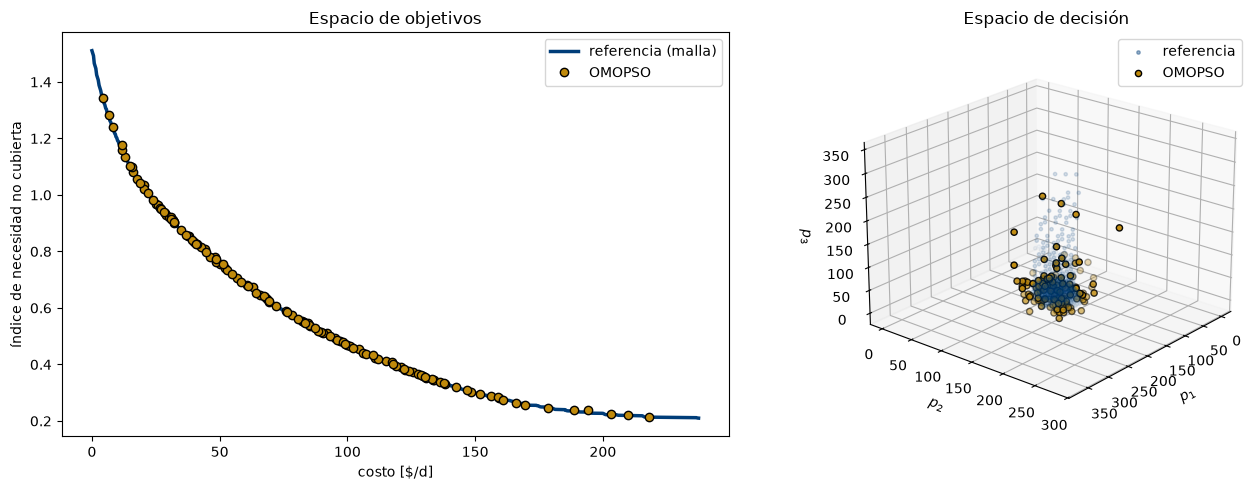

In [19]:
# Esta celda tarda unos 15 segundos
problema_2 = {'CostFunction': fritz_2obj, 'nVar': 3, 'VarMin': 0, 'VarMax': P_MAX}
np.random.seed(42); t0 = time.time()
e_file2, rep2, _ = parOMOPSO(problema_2, parametros)
F2, X2 = frente(e_file2)
escala2 = F_ref2.max(0) - F_ref2.min(0)
dist2 = np.mean([np.min(np.linalg.norm((F_ref2 - f) / escala2, axis=1)) for f in F2])
print(f"{len(F2)} soluciones en {time.time() - t0:.0f} s; distancia media al frente de referencia: {dist2 * 100:.2f} % del tamaño del frente")

fig = plt.figure(figsize=(14, 5))
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(F_ref2[:, 0], F_ref2[:, 1], '-', color='#003D79', lw=2.5, label='referencia (malla)')
ax1.plot(F2[:, 0], F2[:, 1], 'o', mfc='#C08A0B', mec='k', ms=6, label='OMOPSO')
ax1.set_xlabel('costo [$/d]'); ax1.set_ylabel('índice de necesidad no cubierta'); ax1.legend(); ax1.set_title('Espacio de objetivos')
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.scatter(X_ref2[:, 0], X_ref2[:, 1], X_ref2[:, 2], s=6, c='#003D79', alpha=0.4, label='referencia')
ax2.scatter(X2[:, 0], X2[:, 1], X2[:, 2], s=20, c='#C08A0B', edgecolors='k', label='OMOPSO')
ax2.set_xlabel('$p_1$'); ax2.set_ylabel('$p_2$'); ax2.set_zlabel('$p_3$'); ax2.view_init(22, 40); ax2.legend(); ax2.set_title('Espacio de decisión')
plt.tight_layout(); plt.show()

OMOPSO cae sobre la curva sin saber que es una curva, y la cubre de punta a punta. En el espacio de decisión sus soluciones se reparten por la misma
zona que el conjunto de referencia, con algunas sueltas: decisiones distintas pueden dar objetivos casi iguales, y el archivo ε, que mira los objetivos,
no las distingue. Leer solo el espacio de objetivos esconde eso.

### 2.6 La solución de compromiso, en el acuífero

La regla del ejemplo 6: normalizar y elegir la más cercana al origen. Y como siempre, traducirla a bombeos y verla en el acuífero.

compromiso de dos objetivos: p = [244.  201.3  64.7] m³/d (total 510)
  costo 76.3 $/d | índice 0.584 | humedal 0.863 m | pozos [1.94 1.75 0.95] m


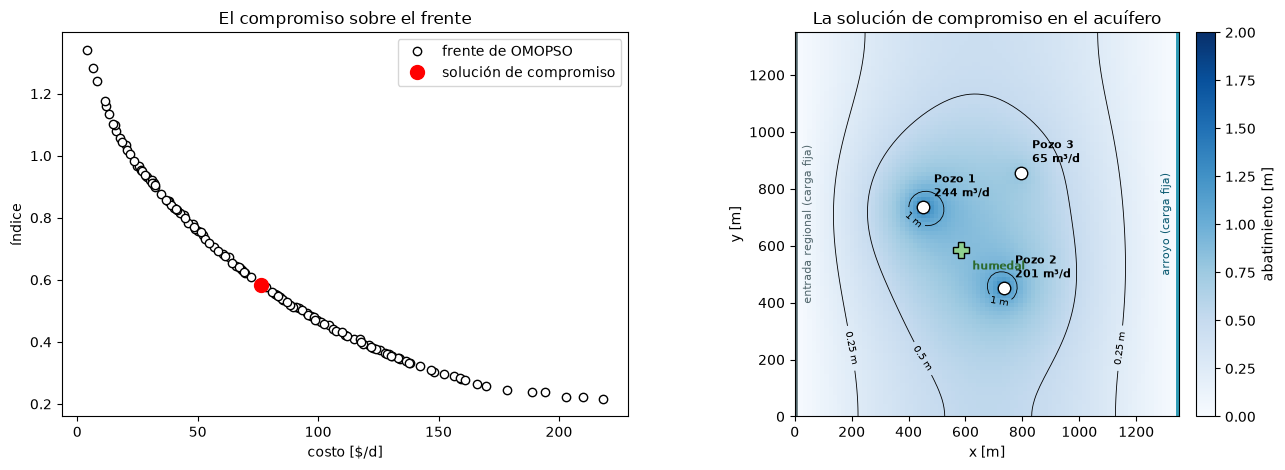

In [20]:
F2n = (F2 - F2.min(0)) / (F2.max(0) - F2.min(0))
k2 = int(np.argmin(np.linalg.norm(F2n, axis=1)))
p2c = X2[k2]; e2c = evaluar(p2c)
print(f"compromiso de dos objetivos: p = {np.round(p2c, 1)} m³/d (total {p2c.sum():.0f})")
print(f"  costo {e2c['costo']:.1f} $/d | índice {e2c['indice']:.3f} | humedal {e2c['humedal']:.3f} m | pozos {np.round(e2c['s'], 2)} m")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.plot(F2[:, 0], F2[:, 1], 'o', mfc='white', mec='k', ms=6, label='frente de OMOPSO')
ax1.plot(*F2[k2], 'o', color='red', ms=10, label='solución de compromiso')
ax1.set_xlabel('costo [$/d]'); ax1.set_ylabel('índice'); ax1.legend(); ax1.set_title('El compromiso sobre el frente')
hidra.mapa(hidra.simular(p2c), titulo='La solución de compromiso en el acuífero', ax=ax2)
plt.tight_layout(); plt.show()

✏️ **Inténtalo:** dale el doble de peso al índice (multiplica la columna 1 de `F2n` por 2 antes de buscar la más cercana al origen). ¿Cómo cambian los bombeos?

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 3 · EL PROBLEMA HIDROGEOLÓGICO CON TRES OBJETIVOS · PROGRAMA 3.5</p>

## 3 · El acuífero de Fritz con tres objetivos (18 min)

El problema completo del cuaderno original tiene tres objetivos: a los dos de la sección 2 se suma el **abatimiento total**. Las restricciones son las
mismas (pozos ≤ 3 m, humedal ≤ 1.25 m), y también la manera de castigarlas.

### 3.1 Definición de las funciones objetivo

#### Función objetivo 1 · abatimiento total

Representa el abatimiento total por el esquema de bombeo utilizado (función objetivo 1 del cuaderno original):

$$
S \;=\; \sum_{i=1}^{M^{p}=3} s_{i}(\mathbf{p}) \;=\; \sum_{i=1}^{3} \sum_{j=1}^{3} \alpha_{ij}\, p_j
$$

**donde** $s_i$ es el abatimiento en el pozo $i$, calculado con la matriz de respuesta del simulador. Es una medida del **daño al acuífero**: cuánto se
deprime el nivel en el campo de pozos.

#### Función objetivo 2 · costo del bombeo  ·  Función objetivo 3 · índice de necesidad no cubierta

Las mismas de la sección 2.1:

$$
\text{Costo}(\mathbf{p}) = \sum_{i=1}^{3} c_i\,p_i\,\big(\text{H}_i - h_i^0 + s_i(\mathbf{p})\big), \qquad
I(\mathbf{p}) = \sum_{i=1}^{3} \exp\bigl(-k\,[c_i^0 + a_i\,p_i]\bigr)
$$

#### El problema

$$
\min_{\mathbf{p}}\; \big(\, S(\mathbf{p}),\ \text{Costo}(\mathbf{p}),\ I(\mathbf{p}) \,\big) \qquad \text{sujeto a} \qquad
s_i(\mathbf{p}) \le 3\ \text{m},\ \ s_h(\mathbf{p}) \le 1.25\ \text{m},\ \ 0 \le p_i \le 500\ \text{m³/d}
$$

El abatimiento total y el costo **suben** al bombear; el índice **baja**. Pero no suben igual: el abatimiento castiga a los pozos que se interfieren
más entre sí, el costo a los pozos hondos y caros. Esa diferencia le da **ancho** al frente.

### 3.2 El frente de referencia

Igual que en la sección 2, una malla da una referencia. Con tres objetivos el filtro de no dominancia es más lento: usamos una malla cada 20 m³/d.

In [21]:
# Esta celda tarda unos 10 segundos
g = np.arange(0, 501, 20.0)
Xg = np.array(np.meshgrid(g, g, g, indexing='ij')).reshape(3, -1).T
Sg = Xg @ alpha.T; ok = (Sg <= 3).all(axis=1) & (Xg @ alpha_h <= S_HUM); Xg, Sg = Xg[ok], Sg[ok]
Fg = np.column_stack([Sg.sum(1), (C_QP * Xg * (GSLEV - H0 + Sg)).sum(1), np.exp(-K_IDX * (C_BASE + A_IDX * Xg)).sum(1)])

def no_dominadas(F):
    # índices de las filas de F que ninguna otra fila domina
    nd = np.ones(len(F), bool)
    for i in range(len(F)):
        if nd[i] and ((F <= F[i]).all(axis=1) & (F < F[i]).any(axis=1)).any():
            nd[i] = False
    return np.flatnonzero(nd)

k3r = no_dominadas(Fg)
F_ref3, X_ref3 = Fg[k3r], Xg[k3r]
r3 = np.corrcoef(F_ref3.T)
print(f"{len(Fg)} decisiones legales; {len(F_ref3)} no dominadas: la superficie de referencia")
print(f"correlaciones sobre el frente: abatimiento-costo {r3[0, 1]:.2f} | abatimiento-índice {r3[0, 2]:.2f} | costo-índice {r3[1, 2]:.2f}")

6809 decisiones legales; 801 no dominadas: la superficie de referencia
correlaciones sobre el frente: abatimiento-costo 0.92 | abatimiento-índice -0.96 | costo-índice -0.94


El abatimiento y el costo van **casi** juntos (correlación alta, pero no 1): por eso el frente es una cinta angosta y no una superficie ancha. Ninguno de
los dos sobra: entre dos decisiones que cuestan lo mismo, una puede abatir bastante menos.

### 3.3 Correr OMOPSO con tres objetivos

In [22]:
def GW_Problem(x, M=10.0):
    # La función objetivo del problema completo: devuelve la columna [abatimiento total, costo, índice]
    e = evaluar(x)
    v = np.maximum(e['s'] - 3, 0).sum() + max(e['humedal'] - S_HUM, 0)      # castigo graduado
    return np.array([[e['s'].sum() + M * v, e['costo'] + M * v, e['indice'] + M * v]]).T

problem3 = {
        'CostFunction': GW_Problem,
        'nVar': 3,
        'VarMin': 0,
        'VarMax': 500,
    }

# Running par_OMOPSO (esta celda tarda unos 30 segundos)
print('Running parOMOPSO ...')
np.random.seed(42); t0 = time.time()
e_file3, rep3, rep_time3 = parOMOPSO(problem3, dict(OMOPSO, MaxIter=100))
F3, X3 = frente(e_file3)
escala3 = F_ref3.max(0) - F_ref3.min(0)
cerca3 = np.mean([np.min(np.linalg.norm((F_ref3 - f) / escala3, axis=1)) for f in F3])
print(f"{len(F3)} soluciones en {time.time() - t0:.0f} s; distancia media a la superficie de referencia: {cerca3 * 100:.2f} %")

Running parOMOPSO ...


272 soluciones en 27 s; distancia media a la superficie de referencia: 1.63 %


### 3.4 Visualizar resultados

#### 3.4.1 Obtener la solución de compromiso óptima

Las celdas del cuaderno original: normalizar cada objetivo y buscar la solución más cercana al origen teórico.

In [23]:
x = []
y = []
z = []

costos = mat_cost(e_file3)

for i in range(0, len(e_file3)):

    mat_vector = costos[:, 0]
    cost_vector = mat_vector[i]
    x.append(cost_vector[0])
    y.append(cost_vector[1])
    z.append(cost_vector[2])

# Normalizar (de 0 = lo mejor del frente a 1 = lo peor)
x = (np.array(x) - np.min(x)) / (np.max(x) - np.min(x))
y = (np.array(y) - np.min(y)) / (np.max(y) - np.min(y))
z = (np.array(z) - np.min(z)) / (np.max(z) - np.min(z))

# Obtener el valor mas cercano al origen teórico
# Calcula la norma (distancia al origen) de cada fila.
# axis=1 indica que la operación se realiza fila por fila.
matriz = np.column_stack((x, y, z))
distancias = np.linalg.norm(matriz, axis=1)

# Encuentra el índice de la fila con la distancia más pequeña
indice_min = np.argmin(distancias)

# Obtiene la fila (x, y, z) correspondiente
fila_mas_cercana = matriz[indice_min]
print("Índice con la menor distancia:", indice_min)
print("Fila más cercana al origen:", np.round(fila_mas_cercana, 3))

Índice con la menor distancia: 230
Fila más cercana al origen: [0.259 0.226 0.51 ]


#### 3.4.2 Visualización

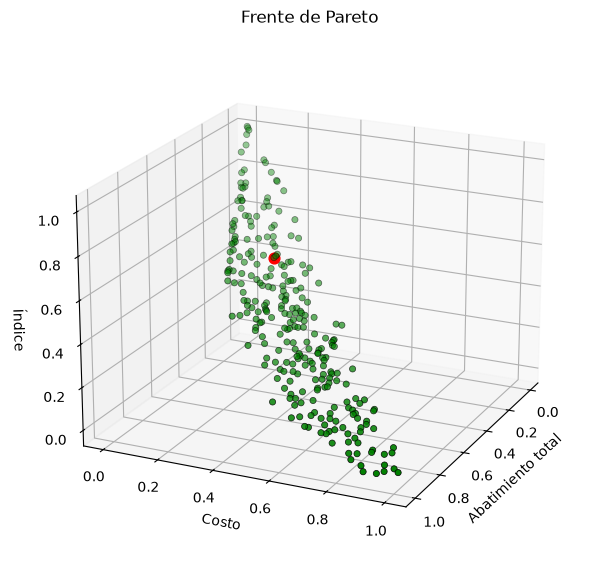

In [24]:
# El frente normalizado y, en rojo, la solución de compromiso (la más cercana al origen)
fig = plt.figure(figsize=(10, 7))
ax = plt.axes(projection="3d")
ax.scatter3D(x, y, z, color="green", edgecolors="black", linewidths=.5)
ax.scatter3D(fila_mas_cercana[0], fila_mas_cercana[1], fila_mas_cercana[2], color="red", s=60)
ax.set_xlabel("Abatimiento total"); ax.set_ylabel("Costo"); ax.set_zlabel("Índice"); plt.title("Frente de Pareto")
ax.view_init(elev=20, azim=25); plt.show()

# La misma figura, para girarla con el mouse
F_norm = np.column_stack([x, y, z])
fig = hidra.frente_3d((F_norm, "Frente de Pareto"), ejes=("Abatimiento total", "Costo", "Índice"),
                      punto=(fila_mas_cercana, "más cercana al origen"), titulo="Frente de Pareto (normalizado) y la solución de compromiso")
fig.show()

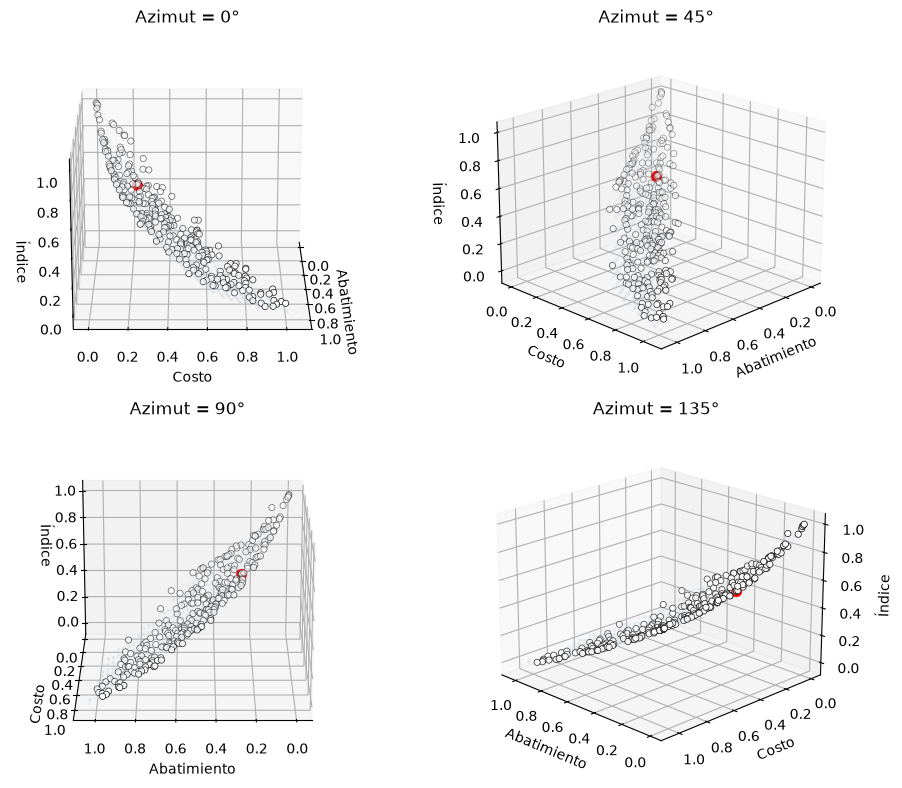

In [25]:
# La superficie de referencia, normalizada con la misma escala que el frente de OMOPSO
Fr = (F_ref3 - F3.min(0)) / (F3.max(0) - F3.min(0))

# La referencia en gris, el frente de OMOPSO en blanco y el punto más cercano al origen en rojo, en cuatro ángulos
azimuts = [0, 45, 90, 135]
fig = plt.figure(figsize=(10, 8))
for i, azim in enumerate(azimuts):
    ax = fig.add_subplot(2, 2, i + 1, projection='3d')
    ax.scatter3D(Fr[:, 0], Fr[:, 1], Fr[:, 2], color="#c9d6e4", s=2, alpha=0.4, label="Referencia (malla)")
    ax.scatter3D(x, y, z, color="white", edgecolors="black", linewidths=.5, label="Frente de Pareto")
    ax.scatter3D(fila_mas_cercana[0], fila_mas_cercana[1], fila_mas_cercana[2], color="red", s=50, label="Punto más cercano")
    ax.set_xlabel("Abatimiento"); ax.set_ylabel("Costo"); ax.set_zlabel("Índice"); ax.set_title(f"Azimut = {azim}°")
    ax.view_init(elev=20, azim=azim)
plt.tight_layout(); plt.show()

# La misma figura para girarla con el mouse; un clic en la leyenda oculta o muestra cada capa
fig = hidra.frente_3d((Fr, "Referencia (malla)", "#9fb3c8", 2), (F_norm, "Frente de Pareto", "white"),
                      ejes=("Abatimiento", "Costo", "Índice"), punto=(fila_mas_cercana, "más cercana al origen"),
                      titulo="OMOPSO (blanco) sobre la referencia (gris)", alto=650)
fig.show()

#### 3.4.3 Las caras del frente

Los tres pares de objetivos en 2-D: lo que se ve al mirar la cinta de frente, desde un lado y desde arriba.

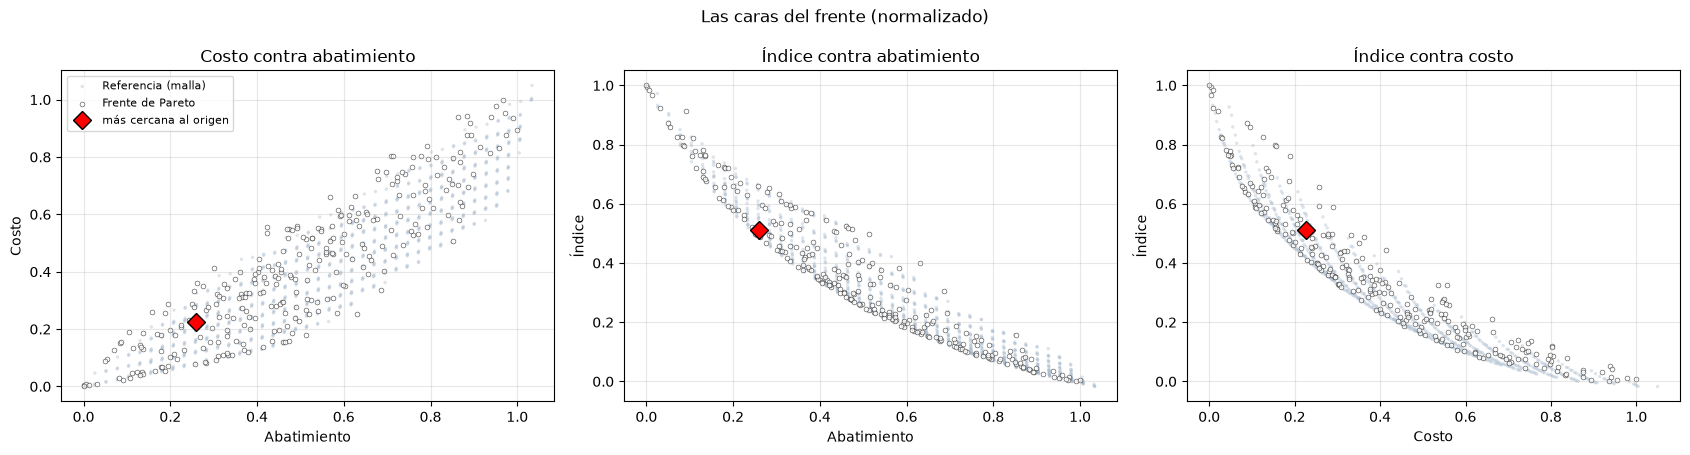

In [26]:
hidra.caras_frente((Fr, "Referencia (malla)", "#9fb3c8", 2), (F_norm, "Frente de Pareto", "white"),
                   ejes=("Abatimiento", "Costo", "Índice"), punto=(fila_mas_cercana, "más cercana al origen"),
                   titulo="Las caras del frente (normalizado)")
plt.show()

Lectura: el frente es una **cinta curva**. A lo largo de ella se intercambia lo mismo que en la sección 2, costo contra necesidad cubierta; a lo ancho,
el abatimiento total contra el costo, es decir, **cómo se reparte** el bombeo entre los pozos: los que se interfieren menos contra los que suben el agua más barato.
Desde el azimut 0° se ve la curva de la sección 2 (costo contra índice); desde 90°, la misma curva contra el abatimiento; desde 45° y 135° se ve el
ancho de la cinta. Las caras (3.4.3) muestran esas vistas en 2-D: la cara costo contra índice es la curva de la sección 2, y la cara abatimiento contra costo, el ancho de la cinta. En la figura interactiva, gírala con el mouse para pasar de una vista a otra y pasa el cursor por un punto para leer sus tres objetivos.

### 3.5 La lectura hidrogeológica

Coordenadas paralelas para ver los tres objetivos a la vez, y el compromiso en el acuífero.

compromiso de tres objetivos: p = [ 26.2 101.5  71.6] m³/d (total 199)
  abatimiento total 1.82 m | costo 48.8 $/d | índice 0.886 | humedal 0.319 m
compromiso de dos objetivos (sección 2.6): p = [244.  201.3  64.7] m³/d (total 510)


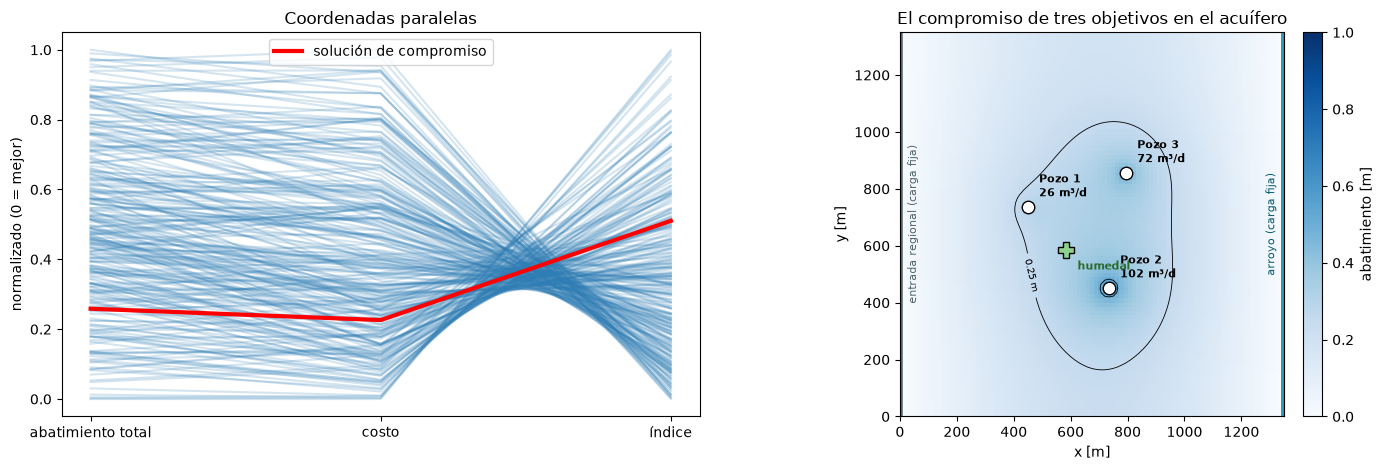

In [27]:
p3c = X3[indice_min]; e3c = evaluar(p3c)
print(f"compromiso de tres objetivos: p = {np.round(p3c, 1)} m³/d (total {p3c.sum():.0f})")
print(f"  abatimiento total {e3c['s'].sum():.2f} m | costo {e3c['costo']:.1f} $/d | índice {e3c['indice']:.3f} | humedal {e3c['humedal']:.3f} m")
print(f"compromiso de dos objetivos (sección 2.6): p = {np.round(p2c, 1)} m³/d (total {p2c.sum():.0f})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
for fila in matriz:
    ax1.plot([0, 1, 2], fila, color='#2E7DB5', alpha=0.2)
ax1.plot([0, 1, 2], matriz[indice_min], color='red', lw=3, label='solución de compromiso')
ax1.set_xticks([0, 1, 2]); ax1.set_xticklabels(['abatimiento total', 'costo', 'índice']); ax1.set_ylabel('normalizado (0 = mejor)')
ax1.set_title('Coordenadas paralelas'); ax1.legend()
hidra.mapa(hidra.simular(p3c), titulo='El compromiso de tres objetivos en el acuífero', ax=ax2)
plt.tight_layout(); plt.show()

La solución de compromiso **no es «la respuesta»**: depende de la normalización y de la regla elegida. Lo que OMOPSO entrega es el menú completo;
la decisión sigue siendo de las personas.

**Qué cambió al pasar de dos a tres objetivos:** el frente ganó una dimensión, y con ella el compromiso cambia: al sumar el abatimiento como objetivo,
la regla del origen castiga ahora también deprimir el acuífero, no solo gastar.

✏️ **Inténtalo:**

1. Dale el doble de peso al abatimiento (multiplica la columna 0 de `matriz` por 2 antes de buscar la más cercana al origen). ¿Qué cambia en los bombeos?
2. Ampliación: cambia en `GW_Problem` el abatimiento total por el abatimiento en el **humedal** (`e['humedal']`) y quita el humedal de las restricciones.
   ¿Cómo cambia la forma del frente? Ahora la autoridad ve cuánto cuesta cada centímetro de humedal.

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 4 · LA TABLA DEJA DE SER MÁGICA · EL PUENTE A LA SESIÓN 4</p>

## 4 · La matriz, su campo y la geología (8 min)

### 4.1 Cada columna de la matriz es un mapa

Desde la sesión 1 la matriz $\alpha$ salió de tres corridas unitarias. Pero cada corrida unitaria da el abatimiento **en todo el acuífero**, no solo en los pozos:
`hidra.campo_respuesta()` guarda los tres mapas. La matriz es solo esos mapas leídos en tres puntos, y la fila del humedal es leerlos en un cuarto.

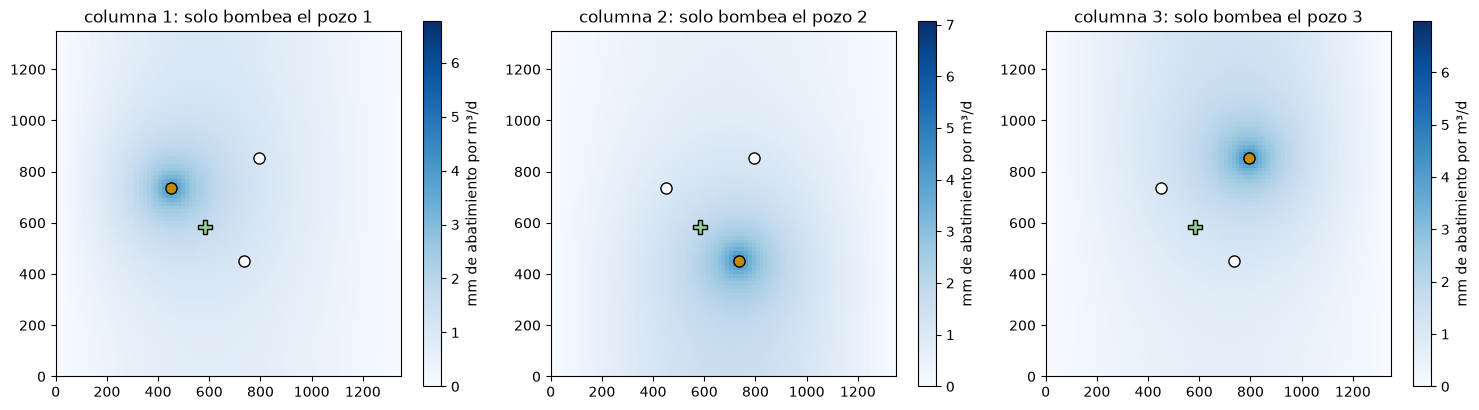

La columna 1 de alpha, leída en los tres pozos: [0.00678 0.00105 0.00115]


In [28]:
campo = hidra.campo_respuesta()                 # (91, 91, 3): un mapa por pozo, en m por cada m³/d
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.6))
for j in range(3):
    im = ejes[j].imshow(campo[:, :, j] * 1000, origin='lower', extent=[0, hidra.LADO, 0, hidra.LADO], cmap='Blues')
    plt.colorbar(im, ax=ejes[j], label='mm de abatimiento por m³/d', shrink=0.85)
    for k, (xx, yy) in enumerate(hidra.pozos_xy()):
        ejes[j].plot(xx, yy, 'o', ms=8, mfc='#C08A0B' if k == j else 'white', mec='k')
    ejes[j].plot(*hidra.humedal_xy(), 'P', ms=10, mfc='#8fd18f', mec='k')
    ejes[j].set_title(f'columna {j + 1}: solo bombea el pozo {j + 1}')
plt.tight_layout(); plt.show()
print("La columna 1 de alpha, leída en los tres pozos:", np.round(alpha[:, 0], 5))

### 4.2 Otra geología, otra matriz, otro frente

El acuífero del curso es **homogéneo**. En la realidad no conocemos la geología punto por punto. `hidra` trae diez geologías heterogéneas posibles, todas
compatibles con lo que sabemos del acuífero. Con cada una, la matriz cambia, y con ella el frente de la sección 2.

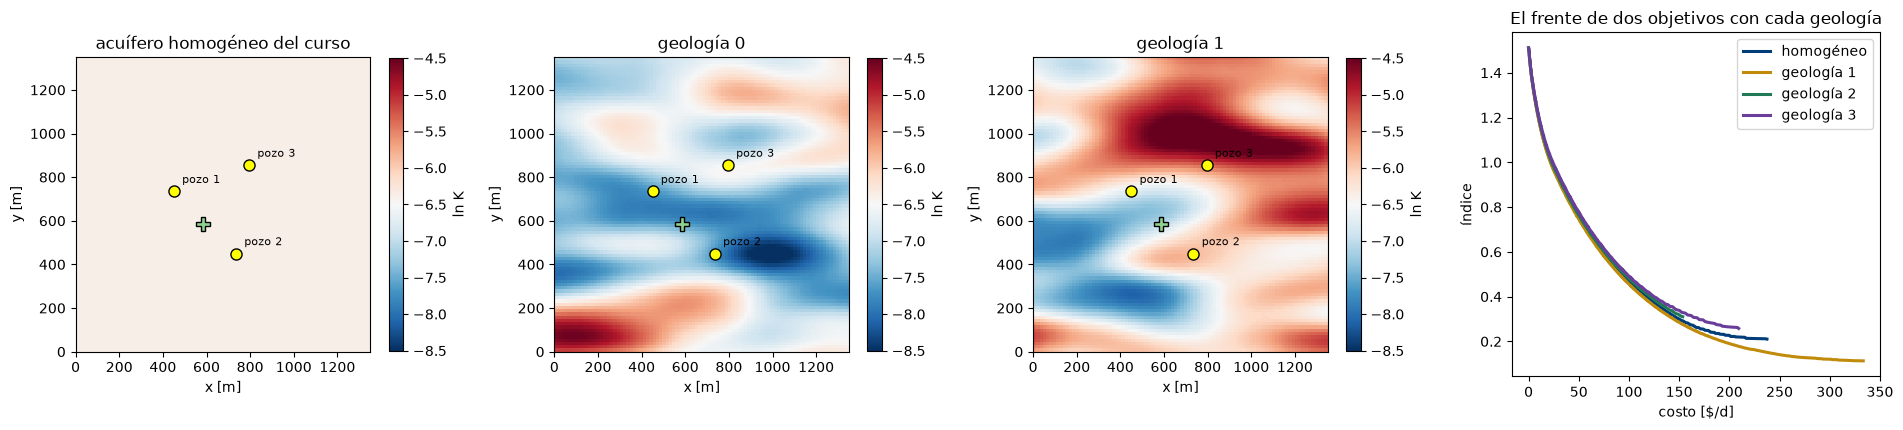

In [29]:
fig, ejes = plt.subplots(1, 4, figsize=(19, 4.4))
for ax, geo in zip(ejes[:3], [None, 0, 1]):
    hidra.mapa_geologia(geo, ax=ax, vmin=-8.5, vmax=-4.5)

ax = ejes[3]
g = np.arange(0, 501, 10.0)
Xg2 = np.array(np.meshgrid(g, g, g, indexing='ij')).reshape(3, -1).T
for geo, color in zip([None, 1, 2, 3], ['#003D79', '#C08A0B', '#1F7A55', '#6A3D9A']):
    al_g, ah_g = hidra.matriz_respuesta(geo), hidra.coeficientes_humedal(geo)
    Sg2 = Xg2 @ al_g.T; ok = (Sg2 <= 3).all(axis=1) & (Xg2 @ ah_g <= S_HUM)
    if not ok.any():
        print(f"geología {geo}: ninguna decisión respeta las reglas"); continue
    Fg2 = np.column_stack([(C_QP * Xg2[ok] * (GSLEV - H0 + Sg2[ok])).sum(1), np.exp(-K_IDX * (C_BASE + A_IDX * Xg2[ok])).sum(1)])
    o = np.lexsort((Fg2[:, 1], Fg2[:, 0])); kk, b = [], np.inf
    for i in o:
        if Fg2[i, 1] < b: kk.append(i); b = Fg2[i, 1]
    ax.plot(Fg2[kk, 0], Fg2[kk, 1], color=color, lw=2.2, label='homogéneo' if geo is None else f'geología {geo}')
ax.set_xlabel('costo [$/d]'); ax.set_ylabel('índice'); ax.set_title('El frente de dos objetivos con cada geología'); ax.legend()
plt.tight_layout(); plt.show()

El frente que le entregamos a la autoridad depende de una geología que **no conocemos**: con otra geología los pozos abaten distinto, el costo cambia y
el humedal limita en otro lugar. La sesión 4 toma muchas geologías a la vez: ¿qué decisión resiste a todas?

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 5 · CIERRE Y TAREA</p>

## 5 · Cierre (5 min)

| | Un objetivo (sesiones 1 y 2) | Varios objetivos (hoy) |
|---|---|---|
| La respuesta | un punto | un frente: el menú de compromisos |
| Comparar decisiones | el número menor gana | dominancia: mejor en todo o empate |
| Validación | contra `linprog` | contra un frente conocido (DTLZ3, ZDT1) o de referencia (malla) |
| Restricciones | penalización | penalización **graduada**: con castigo de muerte el archivo se vacía |
| Dos objetivos | no aplica | una curva |
| Tres objetivos | no aplica | una cinta o una superficie: el frente gana una dimensión |
| Lo que decide | el optimizador | las personas, con el frente en la mano |

### Tarea 3 (asíncrono, unas 2 horas)

`Tarea_3_estudiante.ipynb`, la misma para todos y con los datos de hoy: la ruta de este cuaderno, desde usar OMOPSO con tu propia función objetivo (ZDT1) hasta la dominancia, el frente de referencia, OMOPSO con el castigo bien escalado, tu compromiso, los tres objetivos con la regla de Fritz y el ε del archivo. Es el trabajo asíncrono de la sesión y se califica: se aprueba con 6 de 10; con 2 de los 4 cuadernos de tarea aprobados, el examen del curso está aprobado. Entrega antes del 24 de noviembre.

### Referencias

- Sierra, M. R. y Coello Coello, C. A. (2005). Improving PSO-based multi-objective optimization using crowding, mutation and ε-dominance. *EMO 2005*, LNCS 3410, 505–519.
- Coello Coello, C. A., Pulido, G. T. y Lechuga, M. S. (2004). Handling multiple objectives with particle swarm optimization. *IEEE Transactions on Evolutionary Computation*, 8(3), 256–279.
- Deb, K., Thiele, L., Laumanns, M. y Zitzler, E. (2005). Scalable test problems for evolutionary multiobjective optimization. En *Evolutionary Multiobjective Optimization*, Springer, 105–145. (DTLZ.)
- Zitzler, E., Deb, K. y Thiele, L. (2000). Comparison of multiobjective evolutionary algorithms: empirical results. *Evolutionary Computation*, 8(2), 173–195. (ZDT.)
- Rodríguez-Pretelín, A. y Nowak, W. (2018). Integrating transient behavior as a new dimension to WHPA delineation. *Advances in Water Resources*, 119, 178–187. (rrwpt.)